### IPD441 - Visión por Computador
# Clase 8: Generative Adversarial Networks 
Prof. Nicolás Torres<br/>
<a href="mailto:nicolas.torresr@usm.cl">nicolas.torresr@usm.cl</a><br/>
Ingeniería Civil Telemática<br/>
Departamento de Electrónica<br/>
Universidad Técnica Federico Santa María

# Generative Versus Discriminative Modeling

Hasta hace poco, los modelos discriminativos eran la fuerza impulsora detrás de la mayor parte del progreso en Inteligencia Artificial al ser más fáciles de abordar que los modelos generativos. Por ejemplo, es mucho más fácil entrenar un modelo para predecir si una pintura es de Van Gogh que entrenar un modelo para generar una pintura al estilo de Van Gogh desde cero.

<div align="center">
    <img src="img/discriminative.png" alt="" width="55%" align="center" />
</div>

# Generative Modeling

Los modelos generativos buscan producir nuevos datos que sean similares al conjunto de entrenamiento. Sin embargo, la generación de imágenes, es una tarea increíblemente difícil, considerando la gran cantidad de formas en que se pueden asignar valores de píxeles individuales y el número relativamente pequeño de datos que tenemos a disposición.

<div align="center">
    <img src="img/generative.png" alt="" width="55%" align="center" />
</div>

# The Rise of Generative Modeling

La creatividad se consideraba una capacidad puramente humana que la IA no podía realizar. Sin embargo, a medida que las tecnologías inteligentes han madurado, esta suposición se ha debilitado gradualmente. En los últimos 10 años, muchos de los avances más interesantes en este campo se han producido a través de modelos generativos.

<div align="center">
    <img src="img/midjourney7.png" alt="" width="100%" align="center" />
</div>

# The Beginning

Diciembre de 2014: Ian Goodfellow et al. publican [Generative Adversarial Nets](https://proceedings.neurips.cc/paper/2014/file/5ca3e9b122f61f8f06494c97b1afccf3-Paper.pdf), la primera arquitectura de red neuronal moderna dedicada a la generación de imágenes, en lugar del análisis. 

<div align="center">
    <img src="img/Goodfellow2014.png" alt="" width="100%" align="center" />
</div>


## GAN (2014)

GAN introduce un enfoque único de aprendizaje basado en la teoría de juegos, donde dos subredes, un "generador" y un "discriminador", compiten.

<div align="center">
    <img src="img/in-ou-gans.jpg" alt="" width="60%" align="center" />
</div>

In [1]:
import cv2
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
import keras
import tensorflow as tf

In [3]:
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import (Dense, Reshape, BatchNormalization, 
                                     Conv2DTranspose, Conv2D, Flatten, 
                                     Dropout, UpSampling2D)

In [4]:
from sklearn.datasets import fetch_olivetti_faces

In [5]:
def dataset_olivetti_faces(path, size=(28,28), n_channels=4):
    h,w = size
    oli=np.load(path)
    res = [cv2.resize(o, dsize=(h,w), interpolation=cv2.INTER_CUBIC) for o in oli]
    res=np.array(res)
    if n_channels == 4:
        res=res.reshape(-1,h,w,1).astype(np.float32)
    else:
        res=res.reshape(-1,h,w).astype(np.float32)
    return res

In [6]:
def plot_images(images, n_max_images=24, n_max_col=12, sampler=False, title=None):
    if sampler:
        
        images_to_plot = [images[i] for i in random.sample(range(len(images)), min(len(images), n_max_images))]
        if False:
            if hasattr(images, 'numpy'):
                images = images.numpy()

            if isinstance(images, np.ndarray):
                images = images.tolist()

            if n_max_images is not None:
                images_to_plot = random.sample(images, min(len(images), n_max_images))
            else:
                images_to_plot = images

        images_to_plot = np.array(images_to_plot) if isinstance(images_to_plot, list) else images_to_plot
    else:
        images_to_plot = images if n_max_images is None else images[:n_max_images]
    
    if images_to_plot.shape[-1] == 1:
        images_to_plot = np.squeeze(images_to_plot, axis=-1)

    num_images = len(images_to_plot)
    num_columns = min(num_images, n_max_col)
    num_rows = (num_images - 1) // num_columns + 1

    fig, axes = plt.subplots(num_rows, num_columns, figsize=(16, 4))

    for idx, image in enumerate(images_to_plot):
        row = idx // num_columns
        col = idx % num_columns

        ax = axes[row, col] if num_rows > 1 else axes[col]

        ax.imshow(image, cmap="binary_r")
        ax.axis('off')

    # Ocultar ejes que no contienen imágenes
    for i in range(num_images, num_rows * num_columns):
        row = i // num_columns
        col = i % num_columns

        ax = axes[row, col] if num_rows > 1 else axes[col]
        ax.axis('off')
        ax.set_visible(False)

    if title is not None:
        fig.text(0.5, 0.75, title, ha='center', fontsize=16)
    plt.tight_layout()
    plt.subplots_adjust(top=0.7)
    plt.show()

In [7]:
X_train=dataset_olivetti_faces("olivetti_faces.npy", n_channels=3)
print(X_train.shape)

(400, 28, 28)


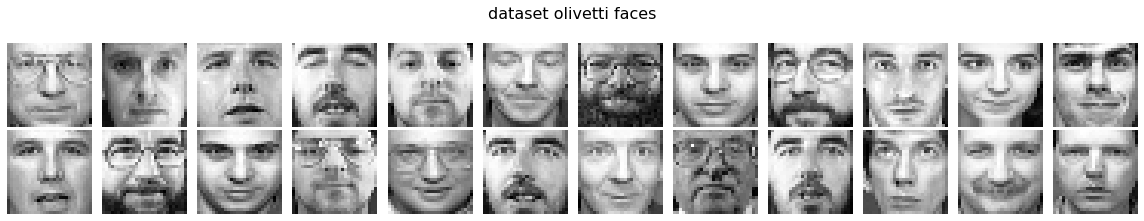

In [8]:
plot_images(X_train, n_max_images=24, n_max_col=12, sampler=True, title="dataset olivetti faces")

# Espacio latente

El espacio latente en la arquitectura de una Generative Adversarial Network (GAN) es desde donde el generador mapea los vectores de números aleatorios como entrada para generar imágenes realistas.

<div align="center">
    <img src="img/latent_space.png" alt="" width="30%" align="center" />
</div>

# ¿Qué relación tiene el espacio latente con las GANs? 🧩

Al entrenar una GAN, el generador no genera imágenes directamente, sino que genera imágenes a partir de un vector `z` sacado al azar desde una distribución conocida, por ejemplo: `z ~ N(0, 1)`.

El generador `G(z)` transforma esa muestra `z` (del espacio latente) en una imagen: `G(z): z → x`. Si lo hace bien, entonces muchas muestras de `z` van a producir imágenes parecidas (en distribución) a las reales.

# La dimensión del espacio latente

En términos simples, si `LATENT_DIM` es 30, cada vector de entrada aleatorio que se alimenta al generador es un vector de 30 números. El generador tomará este vector y lo transformará en una imagen.

Espacios latentes más grandes pueden permitir una mayor variabilidad en las imágenes generadas, pero también pueden requerir más datos y ser más difíciles de entrenar.

In [9]:
LATENT_DIM = 30

In [10]:
# GENERADOR
generator = keras.models.Sequential([
    keras.layers.Dense(32, activation="relu", input_shape=[LATENT_DIM]),
    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dense(256, activation="relu"),
    keras.layers.Dense(28 * 28, activation="sigmoid"),
    keras.layers.Reshape([28, 28])
])

In [11]:
# DISCRIMINADOR
discriminator = keras.models.Sequential([
    keras.layers.Flatten(input_shape=[28, 28]),
    keras.layers.Dense(256, activation="leaky_relu"),
    keras.layers.Dense(128, activation="leaky_relu"),
    keras.layers.Dense(64, activation="leaky_relu"),
    keras.layers.Dense(32, activation="leaky_relu"),
    keras.layers.Dense(1, activation="sigmoid")
])

In [12]:
gan = keras.models.Sequential([generator, discriminator])

In [13]:
def train_gan(gan, 
              dataset, 
              batch_size, 
              codings_size, 
              n_epochs = 50, 
              n_max_images = 24,
              n_max_col = 12,
              sampler = False,
             ):
    generator, discriminator = gan.layers
    for epoch in range(n_epochs):
        for x_batch in dataset:
            # Fase 1 - entrenamiento del discriminador
            noise = tf.random.normal(shape=(batch_size, codings_size))
            generated_images = generator(noise)                                      
            # Reunir igual numero de imagenes generadas (clase 0) y reales (clase 1)
            x_discr = tf.concat([generated_images, x_batch], axis=0)
            y_discr = tf.constant([[0.0]] * batch_size + [[1.0]] * batch_size)
            discriminator.train_on_batch(x_discr, y_discr)
            # ===============================================================================
            # Fase 2 - entrenamiento del generador
            noise = tf.random.normal(shape=(batch_size, codings_size))
            # Las imagenes generadas deben ser etiquetadas como "reales" por el discriminador
            y_gen = tf.constant([[1.0]] * batch_size)
            # Actualizar los pesos del generador
            gan.train_on_batch(noise, y_gen)
    plot_images(generated_images, n_max_images, n_max_col, sampler, title = "Epoch "+str(n_epochs))

In [14]:
discriminator.compile(loss="binary_crossentropy", optimizer="rmsprop")
discriminator.trainable = False
gan.compile(loss="binary_crossentropy", optimizer="rmsprop")

# La importancia del batch size

El batch size es un hiperparámetro crucial en el entrenamiento de GANs. Entre más grande, el entrenamiento es más estable, se genera mayor diversidad, pero se requiere más memoria.

In [15]:
BATCH_SIZE = 200

In [16]:
dataset = tf.data.Dataset.from_tensor_slices(X_train).shuffle(1000)
dataset = dataset.batch(BATCH_SIZE, drop_remainder=True).prefetch(1)

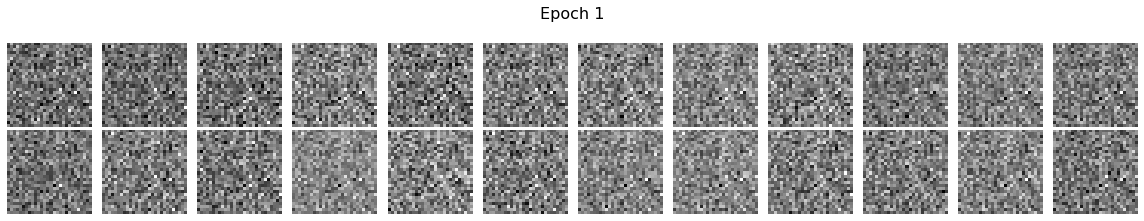

In [17]:
train_gan(gan, dataset, BATCH_SIZE, LATENT_DIM, n_epochs=1, sampler=True)

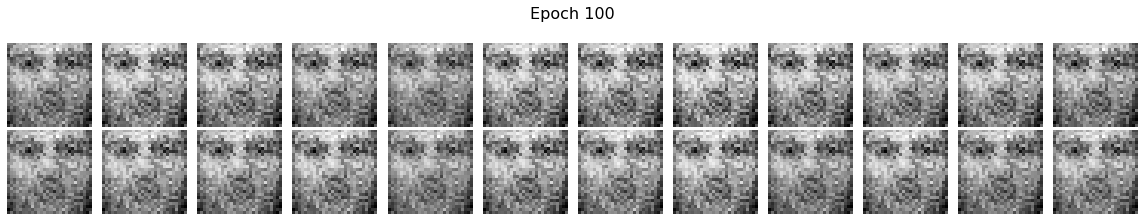

In [18]:
train_gan(gan, dataset, BATCH_SIZE, LATENT_DIM, n_epochs=100, sampler=True)

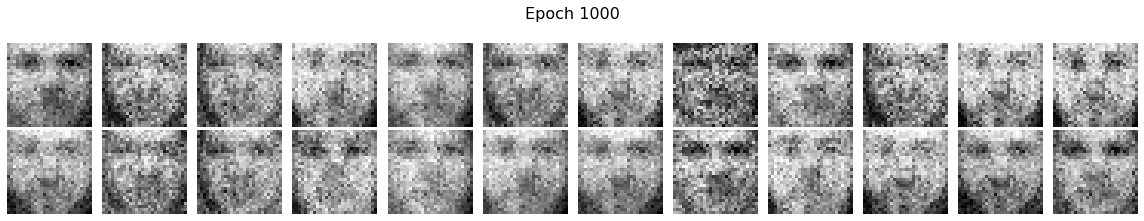

In [19]:
train_gan(gan, dataset, BATCH_SIZE, LATENT_DIM, n_epochs=1000, sampler=True)

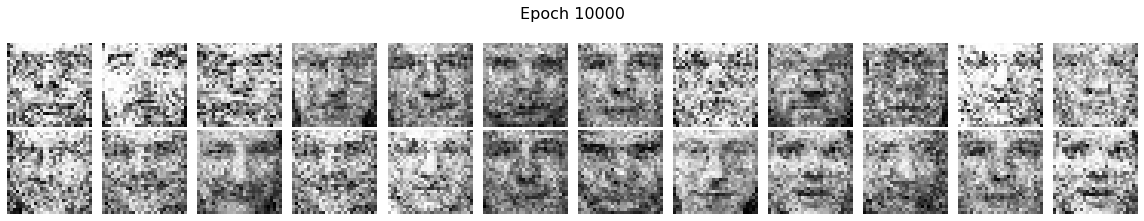

In [20]:
train_gan(gan, dataset, BATCH_SIZE, LATENT_DIM, n_epochs=10000, sampler=True)

## DCGAN (2015)

Nov, 2015: [Unsupervised representation learning with deep convolutional generative adversarial networks](https://arxiv.org/pdf/1511.06434.pdf), describe la primera arquitectura GAN prácticamente utilizable (DCGAN). El artículo también planteó por primera vez la manipulación del espacio latente: ¿los conceptos se asignan a direcciones del espacio latente?

<div align="center">
    <img src="img/morphing.png" alt="" width="100%" align="center" />
</div>


In [21]:
X_train_deep_gan = dataset_olivetti_faces("olivetti_faces.npy")

In [22]:
X_train_deep_gan.shape

(400, 28, 28, 1)

### DCGAN: The Discriminator

El objetivo del discriminador es predecir si una imagen es real o falsa. Por lo tanto, es un problema de clasificación de imágenes supervisada. El conjunto de entrenamiento consta de algunas imágenes reales y otras falsas generadas por el generador. La entropía cruzada binaria se usa como función de pérdida para medir la calidad de las predicciones.

<div align="center">
    <img src="img/discriminator.jpg" alt="" width="60%" align="center" />
</div>

In [23]:
deep_discriminator = keras.models.Sequential([
    keras.layers.Conv2D(64, kernel_size=5, strides=2, padding="SAME",
                        activation=keras.layers.LeakyReLU(0.2),
                        input_shape=[28, 28, 1]),
    keras.layers.Dropout(0.4),
    keras.layers.Conv2D(128, kernel_size=5, strides=2, padding="SAME",
                        activation=keras.layers.LeakyReLU(0.2)),
    keras.layers.Dropout(0.4),
    keras.layers.Flatten(),
    keras.layers.Dense(1, activation="sigmoid")
])

### DCGAN: The Generator

El generador recibe como entrada un vector extraído de una distribución normal estándar multivariada y entrega como resultado una imagen del mismo tamaño que los datos de entrenamiento originales. Durante el aprendizaje, las imágenes generadas pasan por el discriminador para obtener una puntuación. La función de pérdida es simplemente la entropía cruzada binaria entre estas probabilidades y un vector de unos.

<div align="center">
    <img src="img/generator.jpg" alt="" width="60%" align="center" />
</div>

In [ ]:
# Para cargar un modelo entrenado
deep_generator = load_model('dcgan/deep_generator_model.h5')

In [20]:
deep_generator = keras.models.Sequential([
    keras.layers.Dense(7 * 7 * 128, input_shape=[LATENT_DIM]),
    keras.layers.Reshape([7, 7, 128]),
    keras.layers.BatchNormalization(),
    keras.layers.Conv2DTranspose(64, kernel_size=5, strides=2, padding="SAME",
                                 activation="selu"),
    keras.layers.BatchNormalization(),
    keras.layers.Conv2DTranspose(1, kernel_size=5, strides=2, padding="SAME",
                                 activation="tanh"),
])

In [25]:
deep_gan = keras.models.Sequential([deep_generator, deep_discriminator])

In [26]:
deep_discriminator.compile(loss="binary_crossentropy", optimizer="rmsprop")
deep_discriminator.trainable = False
deep_gan.compile(loss="binary_crossentropy", optimizer="rmsprop")

In [27]:
dataset = tf.data.Dataset.from_tensor_slices(X_train_deep_gan)
dataset = dataset.shuffle(1000)
dataset = dataset.batch(BATCH_SIZE, drop_remainder=True).prefetch(1)

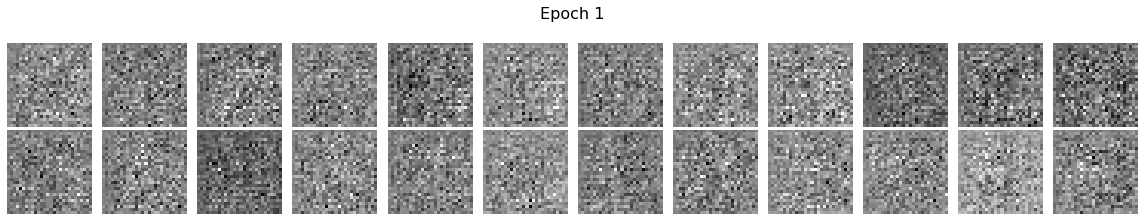

In [24]:
train_gan(deep_gan, dataset, BATCH_SIZE, LATENT_DIM, n_epochs=1, sampler=True)

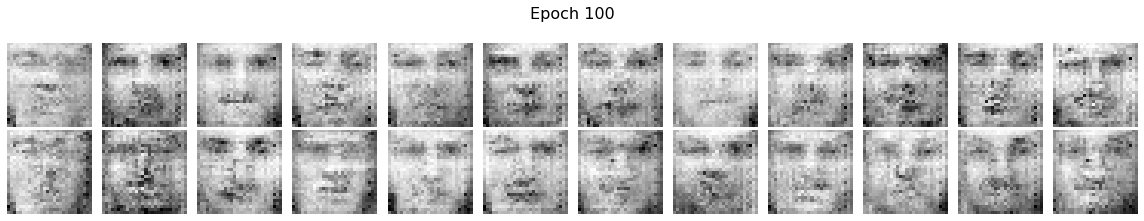

In [25]:
train_gan(deep_gan, dataset, BATCH_SIZE, LATENT_DIM, n_epochs=100, sampler=True)

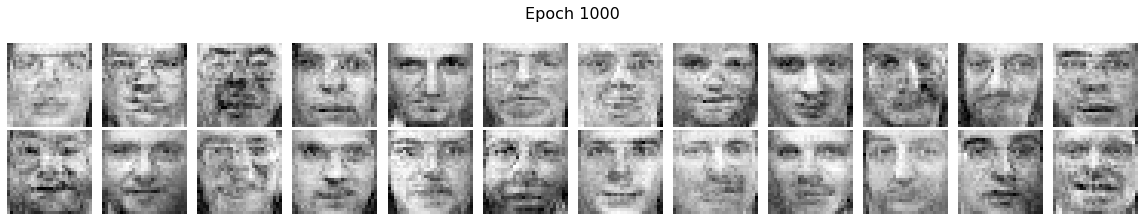

In [26]:
train_gan(deep_gan, dataset, BATCH_SIZE, LATENT_DIM, n_epochs=1000, sampler=True)

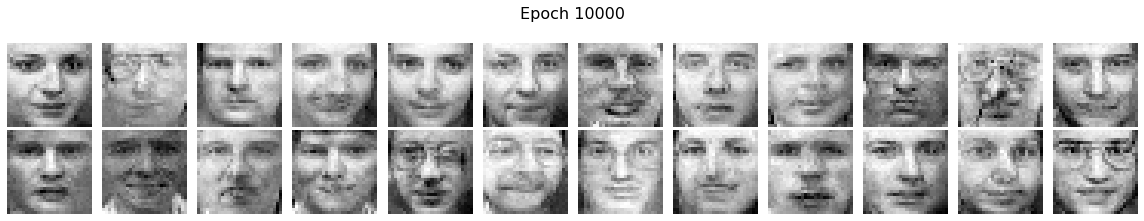

In [27]:
train_gan(deep_gan, dataset, BATCH_SIZE, LATENT_DIM, n_epochs=10000, sampler=True)

In [ ]:
# Guardar el generador entrenado
deep_generator.save('dcgan/deep_generator_model.h5')

In [29]:
# Guardar solo los pesos
deep_generator.save_weights('dcgan/deep_generator_weights.h5')

In [ ]:
# Cargar los pesos
deep_generator.load_weights('dcgan/deep_generator_weights.h5')

In [28]:
def interpolate_images(generator, latent_dim, steps=10):
    """
    Genera una interpolación entre dos puntos aleatorios en el espacio latente.
    
    Args:
        generator: Modelo generador entrenado
        latent_dim: Dimensión del espacio latente
        steps: Número de pasos de interpolación (incluyendo puntos inicial y final)
    
    Returns:
        Figura de matplotlib con la interpolación
    """
    # Generar dos puntos aleatorios en el espacio latente
    z1 = tf.random.normal(shape=(1, latent_dim))
    z2 = tf.random.normal(shape=(1, latent_dim))
    
    # Crear puntos interpolados entre z1 y z2
    alphas = np.linspace(0, 1, steps)
    interpolated_z = []
    
    for alpha in alphas:
        z = alpha * z2 + (1 - alpha) * z1
        interpolated_z.append(z)
    
    # Convertir a tensor y generar imágenes
    interpolated_z = tf.concat(interpolated_z, axis=0)
    interpolated_images = generator(interpolated_z)
    
    # Normalizar imágenes para visualización (convertir de [-1,1] a [0,1])
    interpolated_images = (interpolated_images + 1) / 2.0
    
    # Crear figura para visualización
    fig = plt.figure(figsize=(2*steps, 2))
    
    for i in range(steps):
        # Extraer imagen y eliminar la dimensión del canal si es necesario
        img = interpolated_images[i]
        if img.shape[-1] == 1:
            img = tf.squeeze(img, axis=-1)
        
        # Añadir subplot
        ax = fig.add_subplot(1, steps, i+1)
        if i == 0:
            ax.set_title("Inicio")
        elif i == steps-1:
            ax.set_title("Fin")
        else:
            ax.set_title(f"{i}")
        
        plt.imshow(img, cmap='gray')
        plt.axis('off')
    
    plt.tight_layout()
    return fig

In [29]:
# Función para visualizar múltiples interpolaciones
def show_multiple_interpolations(generator, latent_dim, num_interpolations=3, steps=10):
    """
    Muestra múltiples interpolaciones entre pares de imágenes generadas.
    
    Args:
        generator: Modelo generador entrenado
        latent_dim: Dimensión del espacio latente
        num_interpolations: Número de interpolaciones a mostrar
        steps: Número de pasos por interpolación
    """
    for i in range(num_interpolations):
        fig = interpolate_images(generator, latent_dim, steps)
        fig.suptitle(f"Interpolación {i+1}", fontsize=16)
        plt.show()

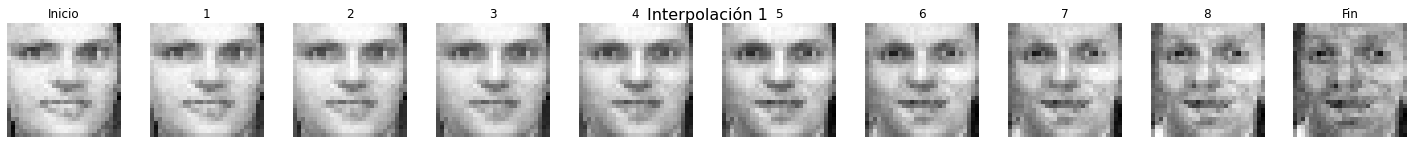

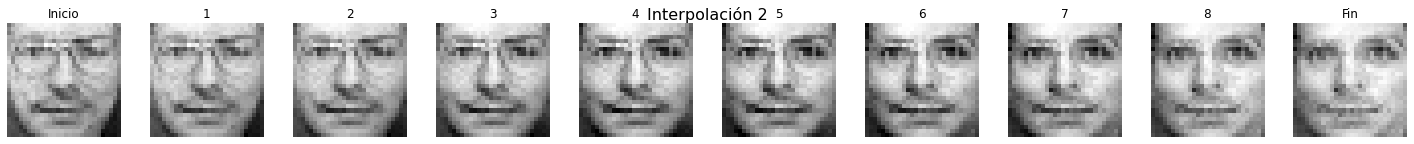

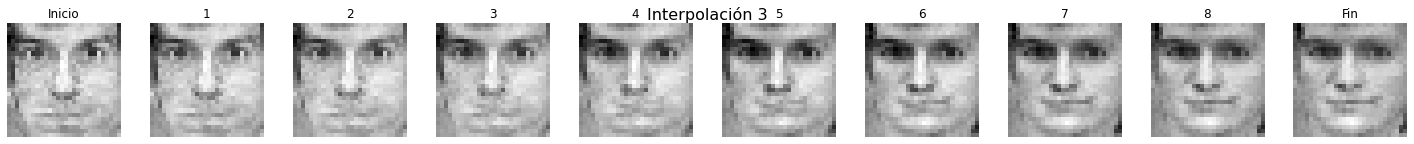

In [30]:
show_multiple_interpolations(deep_generator, LATENT_DIM, num_interpolations=3, steps=10)

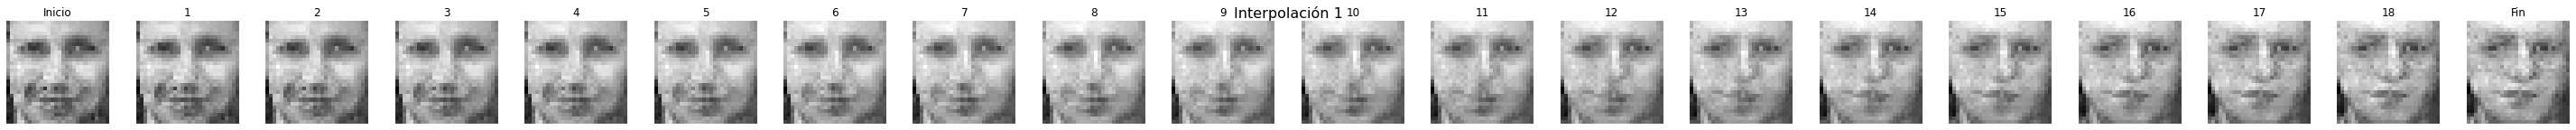

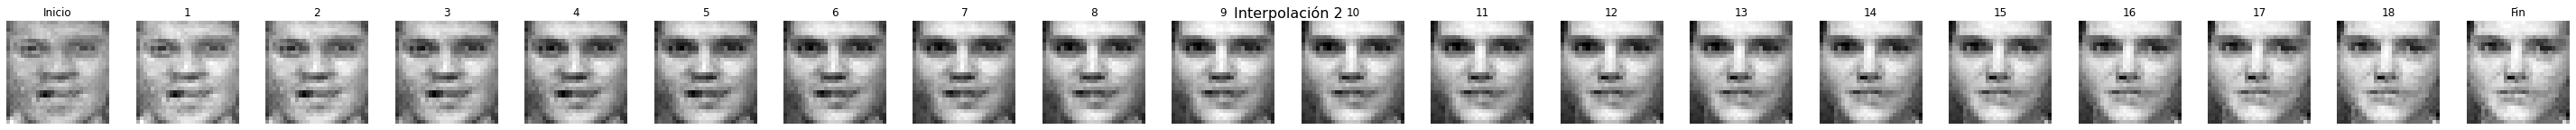

In [32]:
show_multiple_interpolations(deep_generator, LATENT_DIM, num_interpolations=2, steps=20)

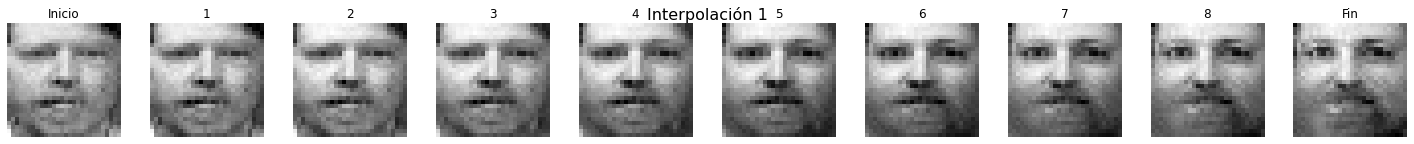

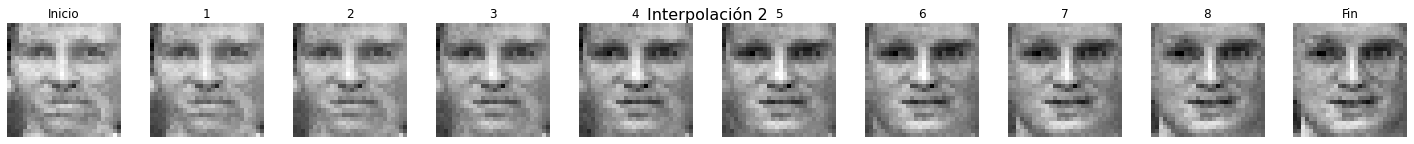

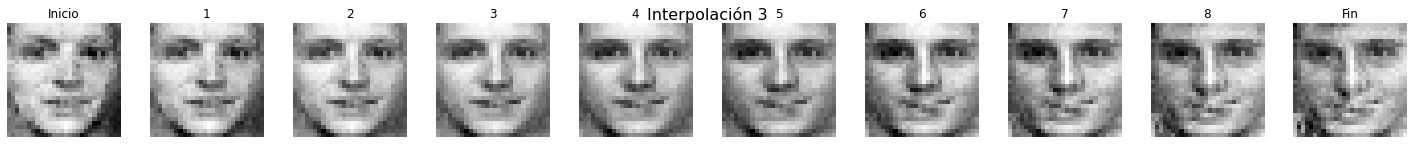

In [32]:
show_multiple_interpolations(deep_generator, LATENT_DIM, num_interpolations=3, steps=10)

## Conditional GAN (2014)

Esta idea, introducida por primera vez en [“Conditional Generative Adversarial Nets”](https://arxiv.org/pdf/1411.1784.pdf) por Mirza y Osindero en 2014, es una extensión relativamente simple de la arquitectura GAN que permite controlar el tipo de imagen que nos gustaría generar, por ejemplo, un rostro masculino o femenino, o un ladrillo grande o pequeño.

<div align="center">
    <img src="img/CGAN_Blond.png" alt="" width="45%" align="center" />
</div>


### CGAN

En una CGAN pasamos información adicional al generador y al crítico relacionada con la etiqueta. En el generador, esto simplemente se agrega a la muestra del espacio latente como un vector one-hot encoded. En el crítico, agregamos la información de la etiqueta como canales adicionales a la imagen RGB. Hacemos esto repitiendo el vector one-hot encoded para tener las mismas dimensiones que las imágenes de entrada.

<div align="center">
    <img src="img/CGAN.png" alt="" width="100%" align="center" />
</div>


In [7]:
from cgan import *

In [8]:
from utils import *

In [9]:
from keras.utils import image_dataset_from_directory

## The CelebA Dataset

Usaremos el conjunto de datos [CelebFaces Attributes (CelebA)](http://mmlab.ie.cuhk.edu.hk/projects/CelebA.html). Se trata de una colección de más de 200.000 imágenes en color de rostros de celebridades, cada una con varias etiquetas (por ejemplo, con sombrero, sonriendo, etc.).

<div align="center">
    <img src="img/CelebFaces.jpg" alt="" width="45%" align="center" />
</div>

In [10]:
attributes = pd.read_csv("list_attr_celeba.csv")

In [11]:
attributes.head()

,File_name,5_o_Clock_Shadow,Arched_Eyebrows,Attractive,Bags_Under_Eyes,Bald,Bangs,Big_Lips,Big_Nose,Black_Hair,...,Sideburns,Smiling,Straight_Hair,Wavy_Hair,Wearing_Earrings,Wearing_Hat,Wearing_Lipstick,Wearing_Necklace,Wearing_Necktie,Young
0,000001.jpg,-1,1,1,-1,-1,-1,-1,-1,-1,...,-1,1,1,-1,1,-1,1,-1,-1,1
1,000002.jpg,-1,-1,-1,1,-1,-1,-1,1,-1,...,-1,1,-1,-1,-1,-1,-1,-1,-1,1
2,000003.jpg,-1,-1,-1,-1,-1,-1,1,-1,-1,...,-1,-1,-1,1,-1,-1,-1,-1,-1,1
3,000004.jpg,-1,-1,1,-1,-1,-1,-1,-1,-1,...,-1,-1,1,-1,1,-1,1,1,-1,1
4,000005.jpg,-1,1,1,-1,-1,-1,1,-1,-1,...,-1,-1,-1,-1,-1,-1,1,-1,-1,1


In [12]:
print(list(attributes.columns))

['File_name', '5_o_Clock_Shadow', 'Arched_Eyebrows', 'Attractive', 'Bags_Under_Eyes', 'Bald', 'Bangs', 'Big_Lips', 'Big_Nose', 'Black_Hair', 'Blond_Hair', 'Blurry', 'Brown_Hair', 'Bushy_Eyebrows', 'Chubby', 'Double_Chin', 'Eyeglasses', 'Goatee', 'Gray_Hair', 'Heavy_Makeup', 'High_Cheekbones', 'Male', 'Mouth_Slightly_Open', 'Mustache', 'Narrow_Eyes', 'No_Beard', 'Oval_Face', 'Pale_Skin', 'Pointy_Nose', 'Receding_Hairline', 'Rosy_Cheeks', 'Sideburns', 'Smiling', 'Straight_Hair', 'Wavy_Hair', 'Wearing_Earrings', 'Wearing_Hat', 'Wearing_Lipstick', 'Wearing_Necklace', 'Wearing_Necktie', 'Young']


In [13]:
CLASSES = 2
LABEL = "Blond_Hair"
IMAGE_SIZE = 64
CHANNELS = 3
BATCH_SIZE = 512
NUM_FEATURES = 64
Z_DIM = 128
LEARNING_RATE = 0.0002
ADAM_BETA_1 = 0.5
ADAM_BETA_2 = 0.999
EPOCHS = 200
CRITIC_STEPS = 3
GP_WEIGHT = 10.0
ADAM_BETA_1 = 0.5
ADAM_BETA_2 = 0.9

In [14]:
labels = attributes[LABEL].tolist()
int_labels = [x if x == 1 else 0 for x in labels]

In [15]:
train_data = utils.image_dataset_from_directory(
    "img_align_celeba",
    labels=int_labels,
    color_mode="rgb",
    image_size=(IMAGE_SIZE, IMAGE_SIZE),
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=42,
    interpolation="bilinear",
)

Found 202599 files belonging to 2 classes.


In [16]:
def preprocess(img):
    img = (tf.cast(img, "float32") - 127.5) / 127.5
    return img

In [17]:
train = train_data.map(
    lambda x, y: (preprocess(x), tf.one_hot(y, depth=CLASSES))
)

In [18]:
train_sample = sample_batch(train)

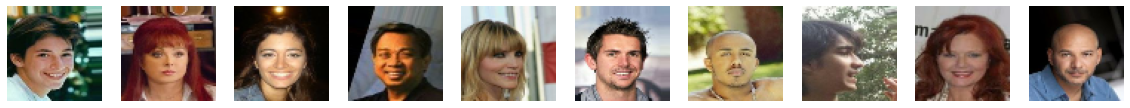

In [19]:
display(train_sample, cmap=None)

In [20]:
critic_input = layers.Input(shape=(IMAGE_SIZE, IMAGE_SIZE, CHANNELS))
label_input = layers.Input(shape=(IMAGE_SIZE, IMAGE_SIZE, CLASSES))
x = layers.Concatenate(axis=-1)([critic_input, label_input])
x = layers.Conv2D(64, kernel_size=4, strides=2, padding="same")(x)
x = layers.LeakyReLU(0.2)(x)
x = layers.Conv2D(128, kernel_size=4, strides=2, padding="same")(x)
x = layers.LeakyReLU()(x)
x = layers.Dropout(0.3)(x)
x = layers.Conv2D(128, kernel_size=4, strides=2, padding="same")(x)
x = layers.LeakyReLU(0.2)(x)
x = layers.Dropout(0.3)(x)
x = layers.Conv2D(128, kernel_size=4, strides=2, padding="same")(x)
x = layers.LeakyReLU(0.2)(x)
x = layers.Dropout(0.3)(x)
x = layers.Conv2D(1, kernel_size=4, strides=1, padding="valid")(x)
critic_output = layers.Flatten()(x)

critic = models.Model([critic_input, label_input], critic_output)

In [21]:
critic.summary()

Model: "model"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_1 (InputLayer)           [(None, 64, 64, 3)]  0           []                               
                                                                                                  
 input_2 (InputLayer)           [(None, 64, 64, 2)]  0           []                               
                                                                                                  
 concatenate (Concatenate)      (None, 64, 64, 5)    0           ['input_1[0][0]',                
                                                                  'input_2[0][0]']                
                                                                                                  
 conv2d (Conv2D)                (None, 32, 32, 64)   5184        ['concatenate[0][0]']        

In [22]:
generator_input = layers.Input(shape=(Z_DIM,))
label_input = layers.Input(shape=(CLASSES,))
x = layers.Concatenate(axis=-1)([generator_input, label_input])
x = layers.Reshape((1, 1, Z_DIM + CLASSES))(x)
x = layers.Conv2DTranspose(
    128, kernel_size=4, strides=1, padding="valid", use_bias=False
)(x)
x = layers.BatchNormalization(momentum=0.9)(x)
x = layers.LeakyReLU(0.2)(x)
x = layers.Conv2DTranspose(
    128, kernel_size=4, strides=2, padding="same", use_bias=False
)(x)
x = layers.BatchNormalization(momentum=0.9)(x)
x = layers.LeakyReLU(0.2)(x)
x = layers.Conv2DTranspose(
    128, kernel_size=4, strides=2, padding="same", use_bias=False
)(x)
x = layers.BatchNormalization(momentum=0.9)(x)
x = layers.LeakyReLU(0.2)(x)
x = layers.Conv2DTranspose(
    64, kernel_size=4, strides=2, padding="same", use_bias=False
)(x)
x = layers.BatchNormalization(momentum=0.9)(x)
x = layers.LeakyReLU(0.2)(x)
generator_output = layers.Conv2DTranspose(
    CHANNELS, kernel_size=4, strides=2, padding="same", activation="tanh"
)(x)
generator = models.Model([generator_input, label_input], generator_output)

In [23]:
generator.summary()

Model: "model_1"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_3 (InputLayer)           [(None, 128)]        0           []                               
                                                                                                  
 input_4 (InputLayer)           [(None, 2)]          0           []                               
                                                                                                  
 concatenate_1 (Concatenate)    (None, 130)          0           ['input_3[0][0]',                
                                                                  'input_4[0][0]']                
                                                                                                  
 reshape (Reshape)              (None, 1, 1, 130)    0           ['concatenate_1[0][0]']    

In [24]:
cgan = ConditionalWGAN(
    critic=critic,
    generator=generator,
    latent_dim=Z_DIM,
    critic_steps=CRITIC_STEPS,
    gp_weight=GP_WEIGHT,
)

In [26]:
cgan.load_weights("./checkpoint_cgan/checkpoint.ckpt");

In [27]:
cgan.compile(
    c_optimizer=optimizers.Adam(
        learning_rate=LEARNING_RATE, beta_1=ADAM_BETA_1, beta_2=ADAM_BETA_2
    ),
    g_optimizer=optimizers.Adam(
        learning_rate=LEARNING_RATE, beta_1=ADAM_BETA_1, beta_2=ADAM_BETA_2
    ),
)

In [28]:
model_checkpoint_callback = callbacks.ModelCheckpoint(
    filepath="./checkpoint_cgan/checkpoint.ckpt",
    save_weights_only=True,
    save_freq="epoch",
    verbose=0,
)

In [31]:
tensorboard_callback = callbacks.TensorBoard(log_dir="./logs")

In [ ]:
history = cgan.fit(
    train,
    epochs=EPOCHS,
    steps_per_epoch=2,
    callbacks=[
        model_checkpoint_callback,
        tensorboard_callback,
        ImageGenerator(num_img=10, latent_dim=Z_DIM),
    ],
)

In [ ]:
generator.save("./cgan/generator")
critic.save("./cgan/critic")

In [29]:
z_sample = np.random.normal(size=(10, Z_DIM))
img1 = cgan.generator.predict([z_sample, np.repeat([[1, 0]], 10, axis=0)])
img2 = cgan.generator.predict([z_sample, np.repeat([[0, 1]], 10, axis=0)])
images = np.concatenate((img1, img2), axis=0)
images = (images + 1.0) / 2.0

1/1 [==============================] - 0s 35ms/step


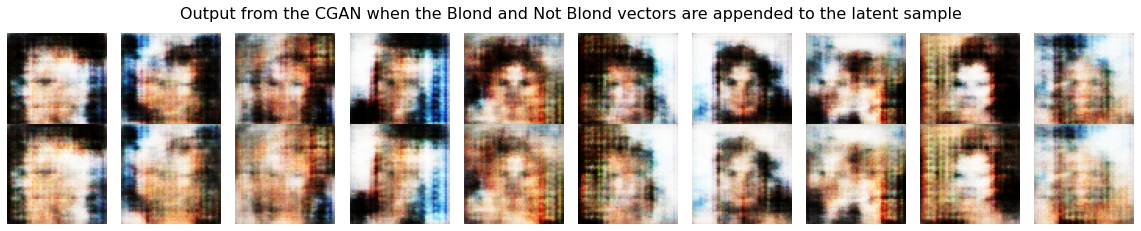

In [30]:
plot_images(images, n_max_images=20, n_max_col=10, title="Output from the CGAN when the Blond and Not Blond vectors are appended to the latent sample")

## ¿Qué limitaciones tenía la GAN original? 
Las GANs originales (incluso DCGAN o CGAN) usaban como función de pérdida la divergencia de Jensen-Shannon (JS), que mide cuán distintas son dos distribuciones.

## Problema:
Cuando el generador no produce imágenes que se parezcan en nada a las reales (al inicio), la JS divergence se satura. El gradiente se vuelve cero y el entrenamiento se estanca o es muy inestable.

# Wasserstein GAN (2017)

[Wasserstein GAN](https://arxiv.org/pdf/1701.07875.pdf) (WGAN), presentada en 2017 por Arjovsky et al., fue uno de los primeros grandes pasos hacia la estabilización del entrenamiento GAN a través de la nueva *función de pérdida de Wasserstein* tanto para el discriminador como para el generador. 

En lugar de usar probabilidad real/fake, usa la distancia Wasserstein (o Earth Mover’s Distance) entre la distribución real y la generada.

<div align="center">
    <img src="img/earth_mover.png" alt="" width="45%" align="center" />
</div>

# Wasserstein GAN with Gradient Penalty (WGAN-GP)

Después de la WGAN original, se propuso la inclusión de la penalización de pérdida por gradiente junto a la función de costo de Wasserstein, que mejora la capacidad de la red para aprender características complejas.

<div align="center">
    <img src="img/WGAN-GP.jpg" alt="" width="50%" align="center" />
</div>

### Interpolating between images

Por temas de eficiencia es imposible calcular el gradiente en todas las imágenes durante el proceso de entrenamiento, por lo que WGAN-GP evalúa el gradiente solo en un puñado de puntos. Para garantizar una mezcla equilibrada, utiliza un conjunto de imágenes interpoladas que se encuentran en puntos elegidos al azar a lo largo de líneas que conectan el lote de imágenes reales con el lote de imágenes falsas por pares.

<div align="center">
    <img src="img/interpolation.jpg" alt="" width="30%" align="center" />
</div>

In [31]:
from wgan_gp import *

In [10]:
train_data = image_dataset_from_directory(
    "img_align_celeba",
    labels=None,
    color_mode="rgb",
    image_size=(64, 64),
    batch_size=512,
    shuffle=True,
    seed=42,
    interpolation="bilinear",
)

Found 202599 files belonging to 1 classes.


In [12]:
train = train_data.map(lambda x: preprocess(x))

In [32]:
critic_input = layers.Input(shape=(IMAGE_SIZE, IMAGE_SIZE, CHANNELS))
x = layers.Conv2D(64, kernel_size=4, strides=2, padding="same")(critic_input)
x = layers.LeakyReLU(0.2)(x)
x = layers.Conv2D(128, kernel_size=4, strides=2, padding="same")(x)
x = layers.LeakyReLU()(x)
x = layers.Dropout(0.3)(x)
x = layers.Conv2D(256, kernel_size=4, strides=2, padding="same")(x)
x = layers.LeakyReLU(0.2)(x)
x = layers.Dropout(0.3)(x)
x = layers.Conv2D(512, kernel_size=4, strides=2, padding="same")(x)
x = layers.LeakyReLU(0.2)(x)
x = layers.Dropout(0.3)(x)
x = layers.Conv2D(1, kernel_size=4, strides=1, padding="valid")(x)
critic_output = layers.Flatten()(x)

critic = models.Model(critic_input, critic_output)

In [33]:
critic.summary()

Model: "model_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_5 (InputLayer)        [(None, 64, 64, 3)]       0         
                                                                 
 conv2d_5 (Conv2D)           (None, 32, 32, 64)        3136      
                                                                 
 leaky_re_lu_8 (LeakyReLU)   (None, 32, 32, 64)        0         
                                                                 
 conv2d_6 (Conv2D)           (None, 16, 16, 128)       131200    
                                                                 
 leaky_re_lu_9 (LeakyReLU)   (None, 16, 16, 128)       0         
                                                                 
 dropout_3 (Dropout)         (None, 16, 16, 128)       0         
                                                                 
 conv2d_7 (Conv2D)           (None, 8, 8, 256)         5245

In [34]:
generator_input = layers.Input(shape=(Z_DIM,))
x = layers.Reshape((1, 1, Z_DIM))(generator_input)
x = layers.Conv2DTranspose(
    512, kernel_size=4, strides=1, padding="valid", use_bias=False
)(x)
x = layers.BatchNormalization(momentum=0.9)(x)
x = layers.LeakyReLU(0.2)(x)
x = layers.Conv2DTranspose(
    256, kernel_size=4, strides=2, padding="same", use_bias=False
)(x)
x = layers.BatchNormalization(momentum=0.9)(x)
x = layers.LeakyReLU(0.2)(x)
x = layers.Conv2DTranspose(
    128, kernel_size=4, strides=2, padding="same", use_bias=False
)(x)
x = layers.BatchNormalization(momentum=0.9)(x)
x = layers.LeakyReLU(0.2)(x)
x = layers.Conv2DTranspose(
    64, kernel_size=4, strides=2, padding="same", use_bias=False
)(x)
x = layers.BatchNormalization(momentum=0.9)(x)
x = layers.LeakyReLU(0.2)(x)
generator_output = layers.Conv2DTranspose(
    CHANNELS, kernel_size=4, strides=2, padding="same", activation="tanh"
)(x)
generator = models.Model(generator_input, generator_output)

In [35]:
generator.summary()

Model: "model_3"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_6 (InputLayer)        [(None, 128)]             0         
                                                                 
 reshape_1 (Reshape)         (None, 1, 1, 128)         0         
                                                                 
 conv2d_transpose_5 (Conv2DT  (None, 4, 4, 512)        1048576   
 ranspose)                                                       
                                                                 
 batch_normalization_4 (Batc  (None, 4, 4, 512)        2048      
 hNormalization)                                                 
                                                                 
 leaky_re_lu_12 (LeakyReLU)  (None, 4, 4, 512)         0         
                                                                 
 conv2d_transpose_6 (Conv2DT  (None, 8, 8, 256)        2097

In [36]:
wgangp = WGANGP(
    critic=critic,
    generator=generator,
    latent_dim=Z_DIM,
    critic_steps=CRITIC_STEPS,
    gp_weight=GP_WEIGHT,
)

In [37]:
wgangp.load_weights("./checkpoint_wgan_gp/checkpoint.ckpt");

In [38]:
wgangp.compile(
    c_optimizer=optimizers.Adam(
        learning_rate=LEARNING_RATE, beta_1=ADAM_BETA_1, beta_2=ADAM_BETA_2
    ),
    g_optimizer=optimizers.Adam(
        learning_rate=LEARNING_RATE, beta_1=ADAM_BETA_1, beta_2=ADAM_BETA_2
    ),
)

In [39]:
model_checkpoint_callback = callbacks.ModelCheckpoint(
    filepath="./checkpoint_wgan_gp/checkpoint.ckpt",
    save_weights_only=True,
    save_freq="epoch",
    verbose=0,
)

In [40]:
tensorboard_callback = callbacks.TensorBoard(log_dir="./logs")

In [ ]:
wgangp.fit(
    train,
    epochs=EPOCHS,
    steps_per_epoch=2,
    callbacks=[
        model_checkpoint_callback,
        tensorboard_callback,
        ImageGenerator(num_img=10, latent_dim=Z_DIM),
    ],
)

In [ ]:
generator.save("./wgan_gp/generator")
critic.save("./wgan_gp/critic")

1/1 [==============================] - 0s 170ms/step


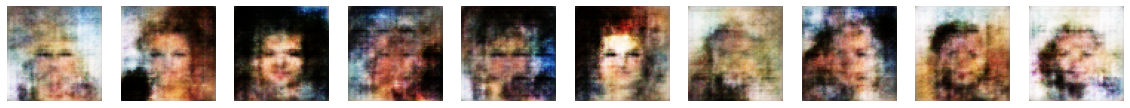

In [41]:
z_sample = np.random.normal(size=(10, Z_DIM))
imgs = wgangp.generator.predict(z_sample)
display(imgs, cmap=None)